# Лабораторна робота №3. Прогин балок і пластин

In [1]:
import time
from math import factorial
import numpy as np
from scipy.sparse import lil_matrix
from scipy.sparse.linalg import spsolve
import matplotlib.pyplot as plt

### Постановка задачі

$$
EJ\,y^{IV}(x) = w(x), \quad x \in [a, b]
$$

На кожному кінці задаються дві умови з набору $y,\ y',\ y'',\ y'''$ (прогин, кут нахилу, момент, поперечна сила).
Далі $EJ = 1$, тобто $y^{IV} = f(x)$.

### П'ятидіагональна прогонка

$$
a_i y_{i-2} + b_i y_{i-1} + c_i y_i + d_i y_{i+1} + e_i y_{i+2} = f_i, \qquad y_i = K_i y_{i+1} + L_i y_{i+2} + M_i
$$

In [2]:
def progonka5(a, b, c, d, e, f):
    n = len(c)
    K = np.zeros(n + 2)          # K[-1], K[-2] = 0
    L = np.zeros(n + 2)
    M = np.zeros(n + 2)
    for i in range(n):
        beta = a[i] * K[i - 2] + b[i]
        den = c[i] + beta * K[i - 1] + a[i] * L[i - 2]
        K[i] = -(d[i] + beta * L[i - 1]) / den
        L[i] = -e[i] / den
        M[i] = (f[i] - beta * M[i - 1] - a[i] * M[i - 2]) / den

    y = np.zeros(n)
    y[n - 1] = M[n - 1]
    y[n - 2] = K[n - 2] * y[n - 1] + M[n - 2]
    for i in range(n - 3, -1, -1):
        y[i] = K[i] * y[i + 1] + L[i] * y[i + 2] + M[i]
    return y


n = 8
a, b, d, e = np.random.rand(4, n)
c = 5 + np.random.rand(n)
a[:2] = b[:1] = d[-1:] = e[-2:] = 0
f = np.random.rand(n)
A = np.diag(c) + np.diag(b[1:], -1) + np.diag(a[2:], -2) + np.diag(d[:-1], 1) + np.diag(e[:-2], 2)
print(np.abs(progonka5(a, b, c, d, e, f) - np.linalg.solve(A, f)).max())

1.3877787807814457e-17


### Різницева схема і граничні умови

$$
y^{IV}_i \approx \frac{y_{i+2} - 4y_{i+1} + 6y_i - 4y_{i-1} + y_{i-2}}{h^4}, \quad i = 2, \dots, n-2
$$

Рядки $0, 1$ і $n-1, n$ системи займають граничні умови (односторонні різниці, як у методичці):

$$
y' \approx \frac{y_1 - y_0}{h}, \quad y'' \approx \frac{y_2 - 2y_1 + y_0}{h^2}, \quad y''' \approx \frac{y_3 - 3y_2 + 3y_1 - y_0}{h^3}
$$

Внутрішня опора $y(x_p) = v$ — рядок $i_p$ замінюється на $y_{i_p} = v$. Зосереджена сила $P$ — $f_{i_p} \mathrel{+}= P/h$.

In [3]:
DIFF = {0: [1], 1: [-1, 1], 2: [1, -2, 1], 3: [-1, 3, -3, 1]}


def set_bc(A, F, h, n, left, right):
    def put(row, start, k, val):
        A[:, row] = 0
        for s, cf in enumerate(DIFF[k]):
            A[start + s - row + 2, row] = cf / h**k
        F[row] = val

    (k1, v1), (k2, v2) = sorted(left)       
    put(0, 0, k1, v1)
    put(1, 0, k2, v2)
    (k1, v1), (k2, v2) = sorted(right)      
    put(n, n - k1, k1, v1)
    put(n - 1, n - k2, k2, v2)


def beam(f, left, right, n=1200, xa=0, xb=1, points=(), loads=()):
    h = (xb - xa) / n
    x = np.linspace(xa, xb, n + 1)
    A = np.zeros((5, n + 1))                 # рядки: a, b, c, d, e
    F = np.zeros(n + 1)
    A[:, 2:n - 1] = np.array([1, -4, 6, -4, 1])[:, None] / h**4
    F[2:n - 1] = f(x[2:n - 1])
    set_bc(A, F, h, n, left, right)
    for xp, v in points:                     # внутрішні опори
        i = round((xp - xa) / h)
        A[:, i] = 0
        A[2, i] = 1
        F[i] = v
    for xp, P in loads:                      # зосереджені сили
        F[round((xp - xa) / h)] += P / h
    return x, progonka5(*A, F)

### Аналітичний розв'язок

In [ ]:
def exact(fpoly, conds, supports=(), loads=()):
    p = np.polynomial.Polynomial(fpoly).integ(4)

    def jump(x, s, k):                      # (x - s)_+^3 / 6 та її похідні
        return np.maximum(np.asarray(x, float) - s, 0)**(3 - k) / factorial(3 - k)

    def part(x, k):                         # відома частина: навантаження
        return p.deriv(k)(x) + sum(P * jump(x, s, k) for s, P in loads)

    def basis(x, k):
        x = np.asarray(x, float)
        cols = [factorial(m) / factorial(m - k) * x**(m - k) if m >= k else 0 * x
                for m in range(4)]
        cols += [jump(x, s, k) for s in supports]
        return np.array(cols)

    S = np.array([basis(xc, k) for k, xc, v in conds])
    C = np.linalg.solve(S, [v - part(xc, k) for k, xc, v in conds])
    return lambda x: part(x, 0) + C @ basis(x, 0)


def show1d(x, y, ye=None, title="", points=()):
    plt.figure(figsize=(9, 5))
    plt.plot(x, y, "--", lw=2, label="чисельний")
    if ye is not None:
        plt.plot(x, ye(x), lw=1, label="аналітичний")
    for xp, v in points:
        plt.plot(xp, v, "r*", ms=10)
    plt.xlabel("x")
    plt.ylabel("y(x)")
    plt.title(title)
    plt.grid()
    plt.legend()
    plt.show()


def check(solver, ye, sizes=(120, 600, 1200)):
    for n in sizes:
        x, y = solver(n)
        print(f"n = {n:5d}: max|y - y_точн| = {np.abs(y - ye(x)).max():.3e}")

### 1. Одновимірна балка

#### Задача 2.3. Жорстко закріплені кінці

$$
y^{IV} = 10^4 \sin 10x, \quad y(0) = 1,\ y'(0) = 0, \quad y(1) = 1,\ y'(1) = 0
$$

$$
y = \sin 10x - 10x + \frac{x^2(20\cos 10 - 6\sin 10 + 40)}{2} - \frac{x^3(60\cos 10 - 12\sin 10 + 60)}{6} + 1
$$

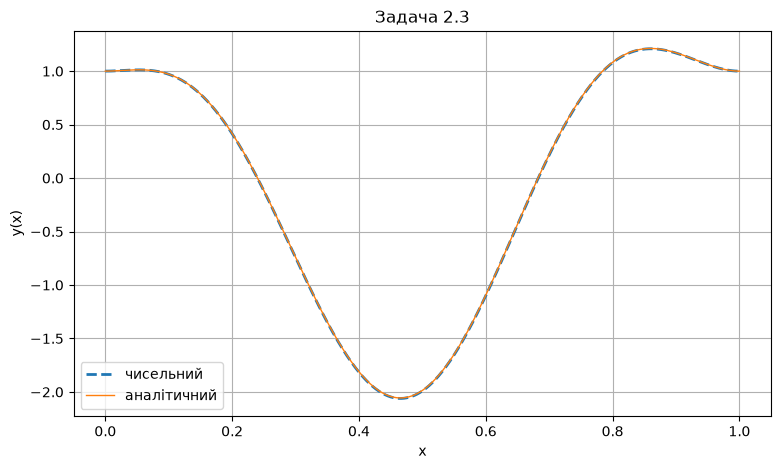

n =   120: max|y - y_точн| = 5.003e-02
n =   600: max|y - y_точн| = 9.905e-03
n =  1200: max|y - y_точн| = 4.948e-03
n =  2400: max|y - y_точн| = 2.487e-03


In [5]:
def task23(n=1200):
    return beam(lambda x: 1e4 * np.sin(10 * x), [(0, 1), (1, 0)], [(0, 1), (1, 0)], n)


y23 = lambda x: (np.sin(10 * x) - 10 * x + x**2 * (20 * np.cos(10) - 6 * np.sin(10) + 40) / 2
                 - x**3 * (60 * np.cos(10) - 12 * np.sin(10) + 60) / 6 + 1)

show1d(*task23(), y23, "Задача 2.3")
check(task23, y23, (120, 600, 1200, 2400))

#### Задача 2.4. Точкове відхилення

$$
y^{IV} = 0, \quad y(0) = y'(0) = 0, \quad y(1) = y'(1) = 0, \quad y(1/3) = -1
$$

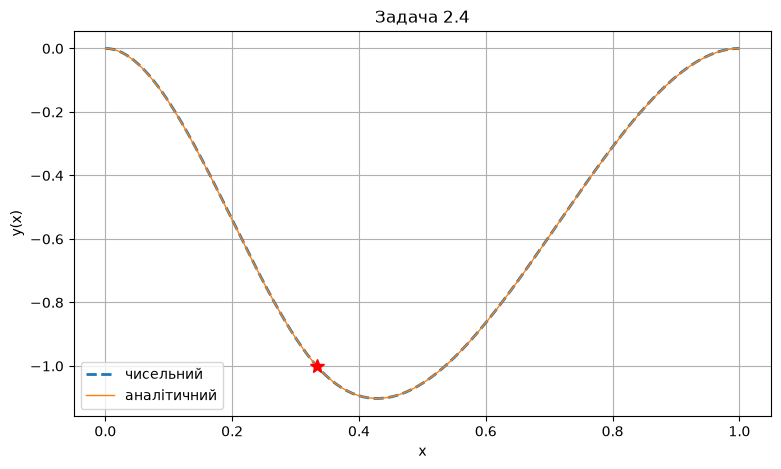

n =   120: max|y - y_точн| = 9.801e-03
n =   600: max|y - y_точн| = 1.908e-03
n =  1200: max|y - y_точн| = 9.508e-04


In [6]:
def task24(n=1200):
    return beam(lambda x: 0 * x, [(0, 0), (1, 0)], [(0, 0), (1, 0)], n, points=[(1 / 3, -1)])


y24 = exact([0], [(0, 0, 0), (1, 0, 0), (0, 1, 0), (1, 1, 0), (0, 1 / 3, -1)], supports=[1 / 3])

show1d(*task24(), y24, "Задача 2.4", points=[(1 / 3, -1)])
check(task24, y24)

#### Задача 2.5. Правий кінець рухається по вертикалі

$$
y^{IV} = -100(1 - x)^2, \quad y(0) = y'(0) = 0, \quad y'(1) = y''(1) = 0
$$

$$
y = -\frac{5x^6}{18} + \frac{5x^5}{3} - \frac{25x^4}{6} + 5x^3 - \frac{5x^2}{2}
$$

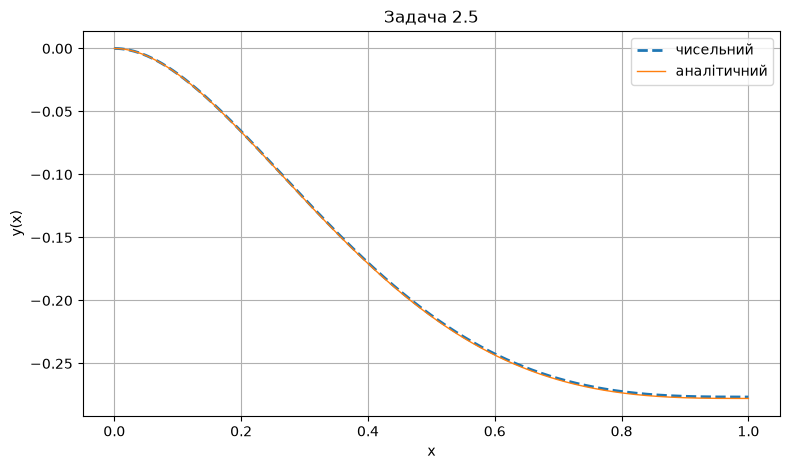

n =   120: max|y - y_точн| = 1.148e-02
n =   600: max|y - y_точн| = 2.311e-03
n =  1200: max|y - y_точн| = 1.155e-03


In [7]:
def task25(n=1200):
    return beam(lambda x: -100 * (1 - x)**2, [(0, 0), (1, 0)], [(1, 0), (2, 0)], n)


y25 = lambda x: -5 * x**6 / 18 + 5 * x**5 / 3 - 25 * x**4 / 6 + 5 * x**3 - 5 * x**2 / 2

show1d(*task25(), y25, "Задача 2.5")
check(task25, y25)

#### Задача 2.6. Три прольоти, закріплені кінці

$$
y^{IV} = -10^4 x, \quad y(0) = y(1/3) = y(2/3) = y(1) = 0, \quad y'(0) = y'(1) = 0
$$

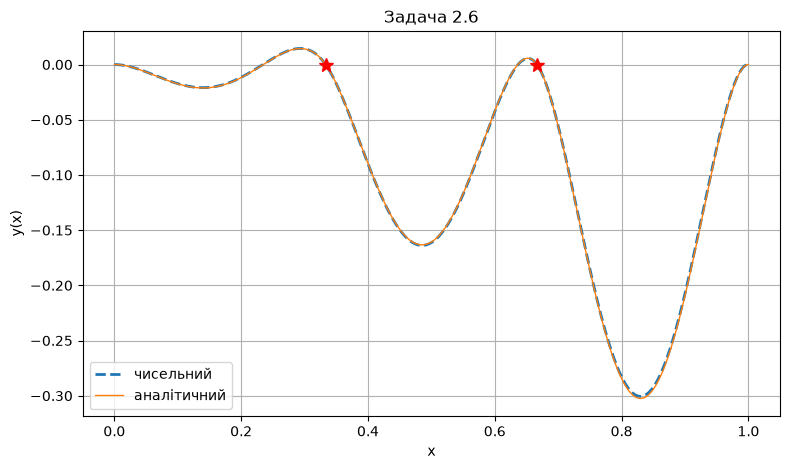

n =   120: max|y - y_точн| = 1.972e-02
n =   600: max|y - y_точн| = 4.015e-03
n =  1200: max|y - y_точн| = 2.012e-03


In [8]:
sup = [(1 / 3, 0), (2 / 3, 0)]


def task26(n=1200):
    return beam(lambda x: -1e4 * x, [(0, 0), (1, 0)], [(0, 0), (1, 0)], n, points=sup)


y26 = exact([0, -1e4], [(0, 0, 0), (1, 0, 0), (0, 1 / 3, 0), (0, 2 / 3, 0), (0, 1, 0), (1, 1, 0)],
            supports=[1 / 3, 2 / 3])

show1d(*task26(), y26, "Задача 2.6", points=sup)
check(task26, y26)

#### Задача 2.7. Три прольоти, рухомі крайні опори

$$
y^{IV} = -10^4 x(1 - x), \quad y'(0) = y(1/3) = y(2/3) = y'(1) = 0, \quad y''(0) = y''(1) = 0
$$

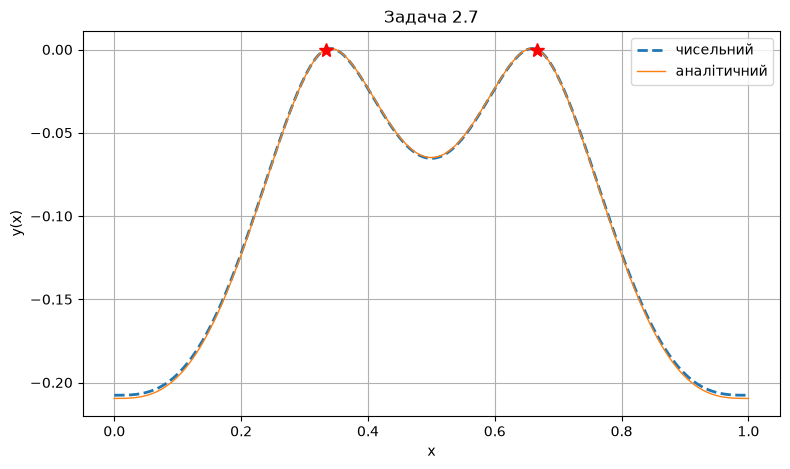

n =   120: max|y - y_точн| = 1.893e-02
n =   600: max|y - y_точн| = 3.844e-03
n =  1200: max|y - y_точн| = 1.925e-03


In [9]:
def task27(n=1200):
    return beam(lambda x: -1e4 * x * (1 - x), [(1, 0), (2, 0)], [(1, 0), (2, 0)], n, points=sup)


y27 = exact([0, -1e4, 1e4], [(1, 0, 0), (2, 0, 0), (0, 1 / 3, 0), (0, 2 / 3, 0), (1, 1, 0), (2, 1, 0)],
            supports=[1 / 3, 2 / 3])

show1d(*task27(), y27, "Задача 2.7", points=sup)
check(task27, y27)

#### Задача 2.8. Консоль (лівий кінець закріплений, правий вільний)

$$
y^{IV} = -x(1 - x), \quad y(0) = y'(0) = 0, \quad y''(1) = y'''(1) = 0
$$

$$
y = \frac{0.025x^6}{9} - \frac{0.025x^5}{3} + \frac{0.25x^3}{9} - \frac{0.125x^2}{3}
$$

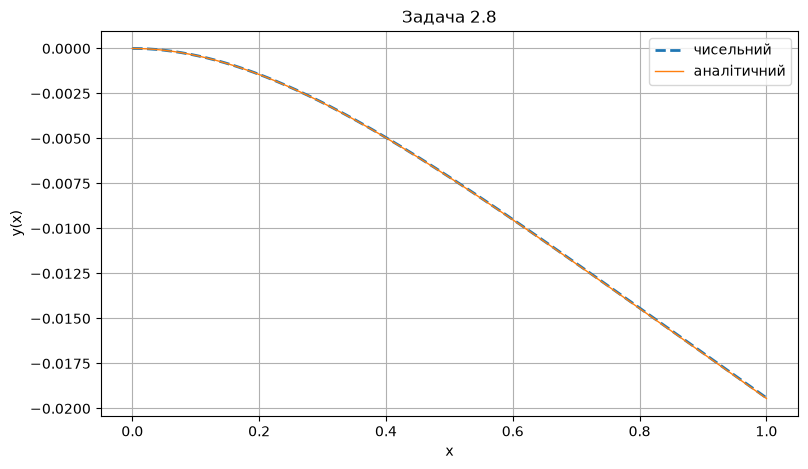

n =   120: max|y - y_точн| = 3.705e-04
n =   600: max|y - y_точн| = 7.035e-05
n =  1200: max|y - y_точн| = 3.414e-05


In [10]:
def task28(n=1200):
    return beam(lambda x: -x * (1 - x), [(0, 0), (1, 0)], [(2, 0), (3, 0)], n)


y28 = lambda x: 0.025 * x**6 / 9 - 0.025 * x**5 / 3 + 0.25 * x**3 / 9 - 0.125 * x**2 / 3

show1d(*task28(), y28, "Задача 2.8")
check(task28, y28)

#### Модифікації: різні типи навантаження

шарнірна, рівномірне q = -1          min y = -0.012969   довідкове = -0.013021   max|y - y_точн| = 5.20e-05
шарнірна, сила P = -1 у центрі       min y = -0.020781   довідкове = -0.020833   max|y - y_точн| = 5.20e-05
консоль, сила на кінці (y'''(1)=1)   min y = -0.332514   довідкове = -0.333333   max|y - y_точн| = 8.20e-04
4 прольоти, трикутне навантаження    min y = -0.239832   довідкове =         —   max|y - y_точн| = 2.38e-03


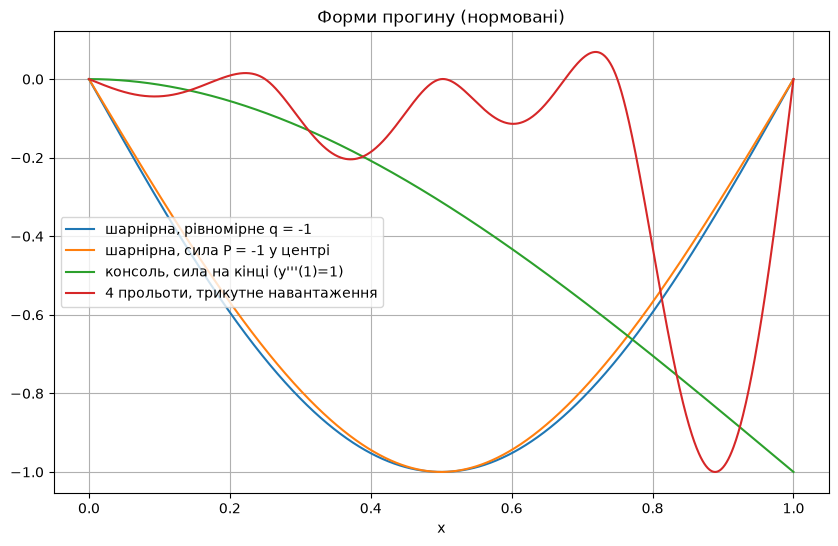

In [11]:
cases = {
    "шарнірна, рівномірне q = -1":       (dict(f=lambda x: -1 + 0 * x, left=[(0, 0), (2, 0)], right=[(0, 0), (2, 0)]),
                                           exact([-1], [(0, 0, 0), (2, 0, 0), (0, 1, 0), (2, 1, 0)]), -5 / 384),
    "шарнірна, сила P = -1 у центрі":    (dict(f=lambda x: 0 * x, left=[(0, 0), (2, 0)], right=[(0, 0), (2, 0)], loads=[(0.5, -1)]),
                                           exact([0], [(0, 0, 0), (2, 0, 0), (0, 1, 0), (2, 1, 0)], loads=[(0.5, -1)]), -1 / 48),
    "консоль, сила на кінці (y'''(1)=1)": (dict(f=lambda x: 0 * x, left=[(0, 0), (1, 0)], right=[(2, 0), (3, 1)]),
                                           exact([0], [(0, 0, 0), (1, 0, 0), (2, 1, 0), (3, 1, 1)]), -1 / 3),
    "4 прольоти, трикутне навантаження": (dict(f=lambda x: -1e4 * x, left=[(0, 0), (2, 0)], right=[(0, 0), (2, 0)],
                                                points=[(0.25, 0), (0.5, 0), (0.75, 0)]),
                                           exact([0, -1e4], [(0, 0, 0), (2, 0, 0), (0, 0.25, 0), (0, 0.5, 0), (0, 0.75, 0), (0, 1, 0), (2, 1, 0)],
                                                 supports=[0.25, 0.5, 0.75]), None),
}

plt.figure(figsize=(10, 6))
for name, (kw, ye, ref) in cases.items():
    x, y = beam(n=1200, **kw)
    plt.plot(x, y / np.abs(y).max(), label=name)
    ref = "—" if ref is None else f"{ref:.6f}"
    print(f"{name:36s} min y = {y.min(): .6f}   довідкове = {ref:>9s}   max|y - y_точн| = {np.abs(y - ye(x)).max():.2e}")
plt.title("Форми прогину (нормовані)")
plt.xlabel("x")
plt.grid()
plt.legend()
plt.show()

Зосереджена сила — це стрибок $y'''$ на $P$, тому в `exact` вона додається як $P\,(x - s)_+^3/6$.

### 2. Двовимірна пластина

$$
\frac{\partial^4 U}{\partial x^4} + 2\frac{\partial^4 U}{\partial x^2 \partial y^2} + \frac{\partial^4 U}{\partial y^4} = f(x, y), \quad (x, y) \in [0, 1]^2
$$

При $h_x = h_y = h$ 13-точкова схема:

$$
\frac{1}{h^4}\Big(20U_{i,j} - 8\sum_{\text{4 сусіди}} U + 2\sum_{\text{4 діагональні}} U + \sum_{\text{4 через один}} U\Big) = f_{i,j}
$$

In [12]:
STENCIL = [(0, 0, 20),
           (-1, 0, -8), (1, 0, -8), (0, -1, -8), (0, 1, -8),
           (-1, -1, 2), (-1, 1, 2), (1, -1, 2), (1, 1, 2),
           (-2, 0, 1), (2, 0, 1), (0, -2, 1), (0, 2, 1)]


def plate(f, n=60, edge="clamped", points=()):
    h = 1 / n
    x = np.linspace(0, 1, n + 1)

    def num(i, j):
        return i * (n + 1) + j

    fixed = {(round(xp / h), round(yp / h)): v for xp, yp, v in points}
    N = (n + 1)**2
    M = lil_matrix((N, N))
    rhs = np.zeros(N)

    for i in range(n + 1):
        for j in range(n + 1):
            k = num(i, j)
            M[k, k] = 1
            if i in (0, n) or j in (0, n):          # U = 0
                pass
            elif i in (1, n - 1):                    # U_x = 0  або  U_xx = 0
                if edge == "hinged":
                    M[k, num(2 if i == 1 else n - 2, j)] = -0.5
            elif j in (1, n - 1):
                if edge == "hinged":
                    M[k, num(i, 2 if j == 1 else n - 2)] = -0.5
            elif (i, j) in fixed:                    # внутрішня опора
                rhs[k] = fixed[(i, j)]
            else:
                for di, dj, c in STENCIL:
                    M[k, num(i + di, j + dj)] = c / h**4
                rhs[k] = f(x[i], x[j])

    U = spsolve(M.tocsr(), rhs).reshape((n + 1, n + 1))
    return x, U


def surface(x, y, U, title, zlabel="U(x, y)", marks=()):
    X, Y = np.meshgrid(x, y, indexing="ij")
    fig = plt.figure(figsize=(10, 7))
    ax = fig.add_subplot(111, projection="3d")
    ax.plot_surface(X, Y, U, cmap="jet", edgecolor="k", lw=0.1)
    for xp, yp, v in marks:
        ax.scatter(xp, yp, v, c="k", s=30)
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_zlabel(zlabel)
    ax.set_title(title)
    plt.show()

Граничні умови займають два крайні ряди вузлів: $U_0 = 0$, а $U_1 = U_0 + h\,U_x = 0$ (защемлення)
або $U_1 = U_2/2$, тобто $U_{xx} = 0$ (шарнір).

#### Задача 3.1. Дві прольоти, опора по лінії $x = 1/2$

$$
\Delta^2 U = -100, \quad U = U_n = 0 \text{ на межі}, \quad U(1/2, y) = 0
$$

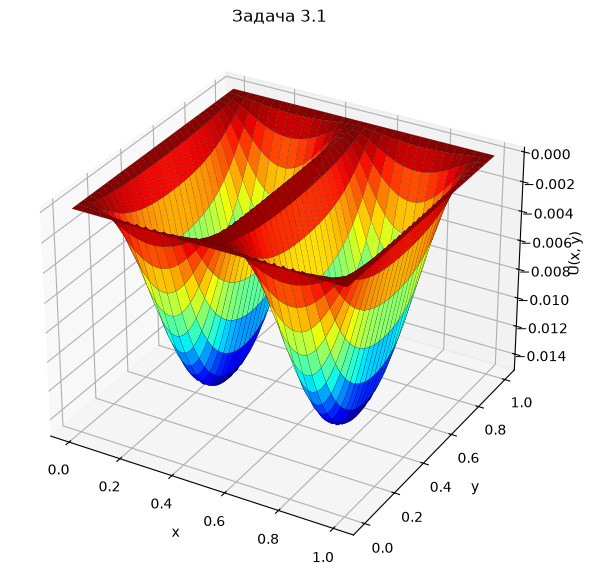

min U = -0.014829750256193078


In [13]:
n = 60
line = [(0.5, y, 0) for y in np.linspace(0, 1, n + 1)]
x, U = plate(lambda x, y: -100, n, points=line)
surface(x, x, U, "Задача 3.1")
print("min U =", U.min())

#### Задача 3.2. Точкова опора в центрі

$$
\Delta^2 U = -100, \quad U = U_n = 0 \text{ на межі}, \quad U(1/2, 1/2) = 0
$$

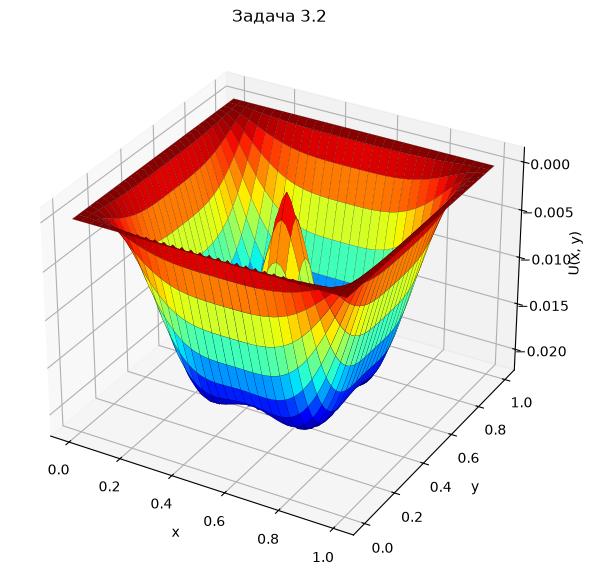

min U = -0.02077301904490326


In [14]:
x, U = plate(lambda x, y: -100, n, points=[(0.5, 0.5, 0)])
surface(x, x, U, "Задача 3.2", marks=[(0.5, 0.5, 0)])
print("min U =", U.min())

#### Задача 3.3. Задані відхилення у чотирьох точках

$$
\Delta^2 U = 0, \quad U\left(\tfrac13, \tfrac13\right) = U\left(\tfrac13, \tfrac23\right) = U\left(\tfrac23, \tfrac23\right) = -1, \quad U\left(\tfrac23, \tfrac13\right) = 2
$$

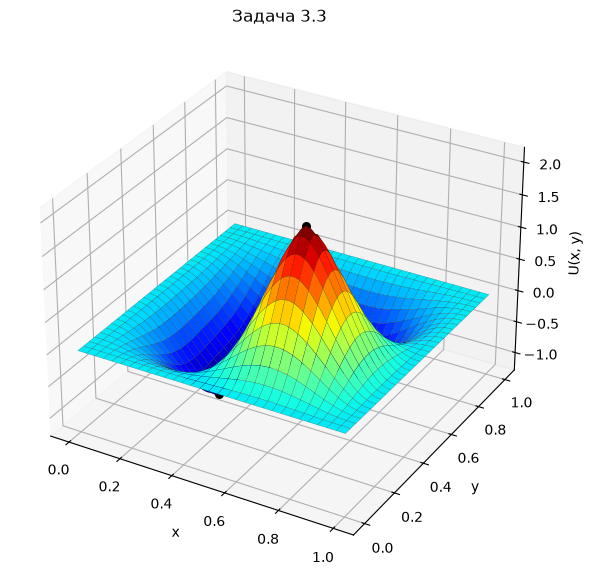

In [15]:
pts = [(1 / 3, 1 / 3, -1), (1 / 3, 2 / 3, -1), (2 / 3, 1 / 3, 2), (2 / 3, 2 / 3, -1)]
x, U = plate(lambda x, y: 0, n, points=pts)
surface(x, x, U, "Задача 3.3", marks=pts)

#### Перевірка: пластина без внутрішніх опор, $q = 1$

Довідкові значення прогину в центрі квадратної пластини: $0.00126\,q$ (защемлена), $0.00406\,q$ (шарнірна, ряд Нав'є).

In [16]:
m = np.arange(1, 200, 2)
Mm, Kk = np.meshgrid(m, m)
navier = (16 / (np.pi**6 * Mm * Kk * (Mm**2 + Kk**2)**2) * np.sin(Mm * np.pi / 2) * np.sin(Kk * np.pi / 2)).sum()

for n_ in [20, 40, 80, 120]:
    _, Uc = plate(lambda x, y: 1, n_)
    _, Uh = plate(lambda x, y: 1, n_, edge="hinged")
    print(f"n = {n_:3d}: защемлена {Uc.max():.6f} (0.00126),  шарнірна {Uh.max():.6f} (Нав'є {navier:.6f})")

n =  20: защемлена 0.001015 (0.00126),  шарнірна 0.003351 (Нав'є 0.004062)


n =  40: защемлена 0.001139 (0.00126),  шарнірна 0.003712 (Нав'є 0.004062)
n =  80: защемлена 0.001202 (0.00126),  шарнірна 0.003889 (Нав'є 0.004062)
n = 120: защемлена 0.001223 (0.00126),  шарнірна 0.003947 (Нав'є 0.004062)


#### Метод верхньої релаксації

In [17]:
def relax(f, n, alpha=1.85, eps=1e-9):
    h = 1 / n
    x = np.linspace(0, 1, n + 1)
    U = np.zeros((n + 1, n + 1))
    F = np.array([[f(a, b) for b in x] for a in x]) * h**4
    it, err = 0, 1
    while err > eps:
        it += 1
        err = 0
        for i in range(2, n - 1):
            for j in range(2, n - 1):
                s = (U[i - 2, j] + U[i + 2, j] + U[i, j - 2] + U[i, j + 2]
                     - 8 * (U[i - 1, j] + U[i + 1, j] + U[i, j - 1] + U[i, j + 1])
                     + 2 * (U[i - 1, j - 1] + U[i - 1, j + 1] + U[i + 1, j - 1] + U[i + 1, j + 1]))
                new = U[i, j] + alpha * ((F[i, j] - s) / 20 - U[i, j])
                err = max(err, abs(new - U[i, j]))
                U[i, j] = new
    return x, U, it


for n_ in [10, 20, 30]:
    start = time.time()
    _, Ur, it = relax(lambda x, y: -100, n_)
    t_relax = time.time() - start
    start = time.time()
    _, Ud = plate(lambda x, y: -100, n_)
    t_direct = time.time() - start
    print(f"n = {n_}: ітерацій {it:5d}, релаксація {t_relax:.2f} с, spsolve {t_direct:.3f} с, "
          f"різниця {np.abs(Ur - Ud).max():.1e}")

n = 10: ітерацій   333, релаксація 0.02 с, spsolve 0.002 с, різниця 1.2e-08
n = 20: ітерацій  1346, релаксація 0.49 с, spsolve 0.006 с, різниця 3.6e-08
n = 30: ітерацій  3504, релаксація 3.11 с, spsolve 0.012 с, різниця 4.2e-07


### 3. Полярні координати (осесиметричний випадок)

$$
\varphi^{IV} + \frac{2}{r}\varphi''' - \frac{1}{r^2}\varphi'' + \frac{1}{r^3}\varphi' = f(r), \quad r \in [1, 2]
$$

$$
\varphi''' \approx \frac{\varphi_{i+2} - 2\varphi_{i+1} + 2\varphi_{i-1} - \varphi_{i-2}}{2h^3}, \quad
\varphi'' \approx \frac{\varphi_{i+1} - 2\varphi_i + \varphi_{i-1}}{h^2}, \quad
\varphi' \approx \frac{\varphi_{i+1} - \varphi_{i-1}}{2h}
$$

$$
a_i = \frac{1}{h^4} - \frac{1}{r_ih^3}, \quad
b_i = -\frac{4}{h^4} + \frac{2}{r_ih^3} - \frac{1}{r_i^2h^2} - \frac{1}{2r_i^3h}, \quad
c_i = \frac{6}{h^4} + \frac{2}{r_i^2h^2},
$$

$$
d_i = -\frac{4}{h^4} - \frac{2}{r_ih^3} - \frac{1}{r_i^2h^2} + \frac{1}{2r_i^3h}, \quad
e_i = \frac{1}{h^4} + \frac{1}{r_ih^3}
$$

Аналітичний розв'язок: $\varphi = C_1 + C_2\ln r + C_3 r^2 + C_4 r^2\ln r + \dfrac{q r^4}{64}$ (для $f = q$).

In [18]:
def polar(f, left, right, n=1000, ra=1, rb=2):
    h = (rb - ra) / n
    r = np.linspace(ra, rb, n + 1)
    ri = r[2:n - 1]
    A = np.zeros((5, n + 1))
    F = np.zeros(n + 1)
    A[0, 2:n - 1] = 1 / h**4 - 1 / (ri * h**3)
    A[1, 2:n - 1] = -4 / h**4 + 2 / (ri * h**3) - 1 / (ri**2 * h**2) - 1 / (2 * ri**3 * h)
    A[2, 2:n - 1] = 6 / h**4 + 2 / (ri**2 * h**2)
    A[3, 2:n - 1] = -4 / h**4 - 2 / (ri * h**3) - 1 / (ri**2 * h**2) + 1 / (2 * ri**3 * h)
    A[4, 2:n - 1] = 1 / h**4 + 1 / (ri * h**3)
    F[2:n - 1] = f(ri)
    set_bc(A, F, h, n, left, right)
    return r, progonka5(*A, F)


def exact_polar(conds, q=0):
    def basis(r, k):
        r = np.asarray(r, float)
        lr = np.log(r)
        return np.array({0: [1 + 0 * r, lr, r**2, r**2 * lr],
                         1: [0 * r, 1 / r, 2 * r, 2 * r * lr + r],
                         2: [0 * r, -1 / r**2, 2 + 0 * r, 2 * lr + 3]}[k])

    part = [lambda r: q * r**4 / 64, lambda r: q * r**3 / 16, lambda r: 3 * q * r**2 / 16]
    S = np.array([basis(rc, k) for k, rc, v in conds])
    C = np.linalg.solve(S, [v - part[k](rc) for k, rc, v in conds])
    return lambda r: C @ basis(r, 0) + part[0](r)


def show_polar(f, left, right, title, q=0):
    r, p = polar(f, left, right)
    pe = exact_polar([(k, 1, v) for k, v in left] + [(k, 2, v) for k, v in right], q)

    th = np.linspace(0, 2 * np.pi, 120)
    R, TH = np.meshgrid(r[::10], th)
    fig = plt.figure(figsize=(13, 5))
    fig.suptitle(title)
    ax = fig.add_subplot(1, 2, 1)
    ax.plot(r, p, "--", lw=2, label="чисельний")
    ax.plot(r, pe(r), lw=1, label="аналітичний")
    ax.set_xlabel("r")
    ax.set_ylabel("φ(r)")
    ax.grid()
    ax.legend()
    ax = fig.add_subplot(1, 2, 2, projection="3d")
    ax.plot_surface(R * np.cos(TH), R * np.sin(TH), np.tile(p[::10], (len(th), 1)), cmap="jet")
    plt.show()

    for n_ in [100, 500, 1000]:
        r, p = polar(f, left, right, n_)
        print(f"n = {n_:5d}: max|φ - φ_точн| = {np.abs(p - pe(r)).max():.3e}")

#### Задача 4.4. Обидва краї кільця защемлені

$$
\varphi(1) = 1,\ \varphi'(1) = 0, \quad \varphi(2) = 0,\ \varphi'(2) = 0
$$

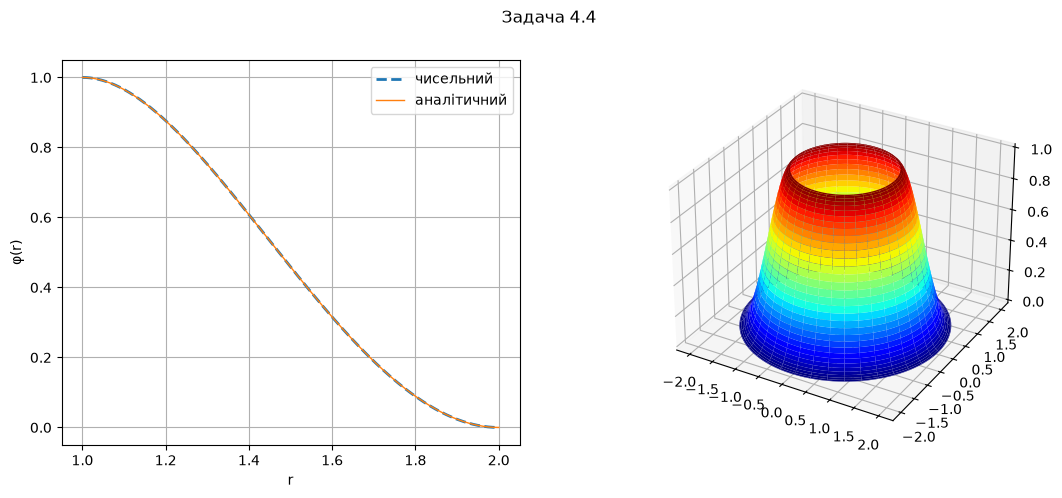

n =   100: max|φ - φ_точн| = 3.609e-03
n =   500: max|φ - φ_точн| = 7.090e-04
n =  1000: max|φ - φ_точн| = 3.538e-04


In [19]:
zero = lambda r: 0 * r
show_polar(zero, [(0, 1), (1, 0)], [(0, 0), (1, 0)], "Задача 4.4")

#### Задача 4.5. Внутрішній край шарнірний

$$
\varphi(1) = 1,\ \varphi''(1) = 0, \quad \varphi(2) = 0,\ \varphi'(2) = 0
$$

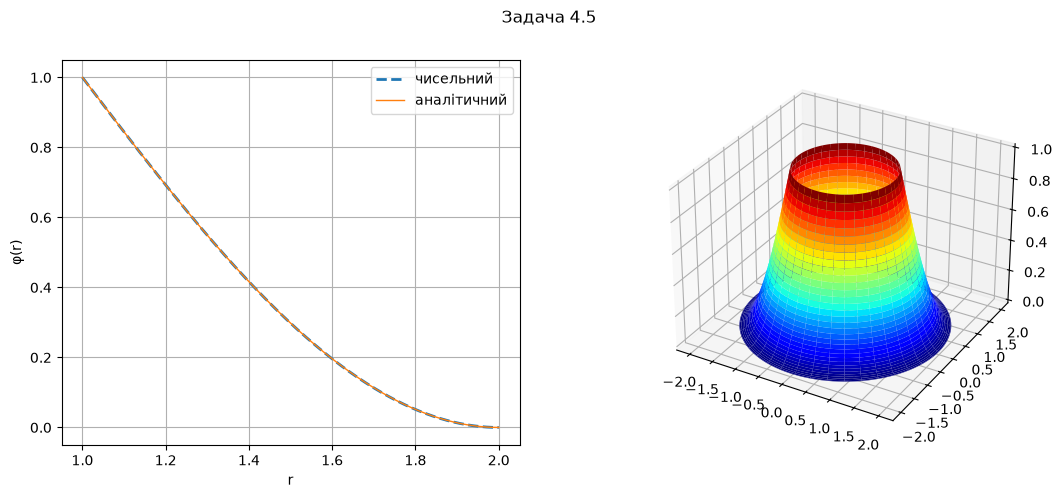

n =   100: max|φ - φ_точн| = 2.133e-03
n =   500: max|φ - φ_точн| = 4.226e-04
n =  1000: max|φ - φ_точн| = 2.108e-04


In [20]:
show_polar(zero, [(0, 1), (2, 0)], [(0, 0), (1, 0)], "Задача 4.5")

#### Задача 4.6. Внутрішній край ковзає по вертикалі

$$
\varphi'(1) = \varphi''(1) = 0, \quad \varphi(2) = \varphi'(2) = 1
$$

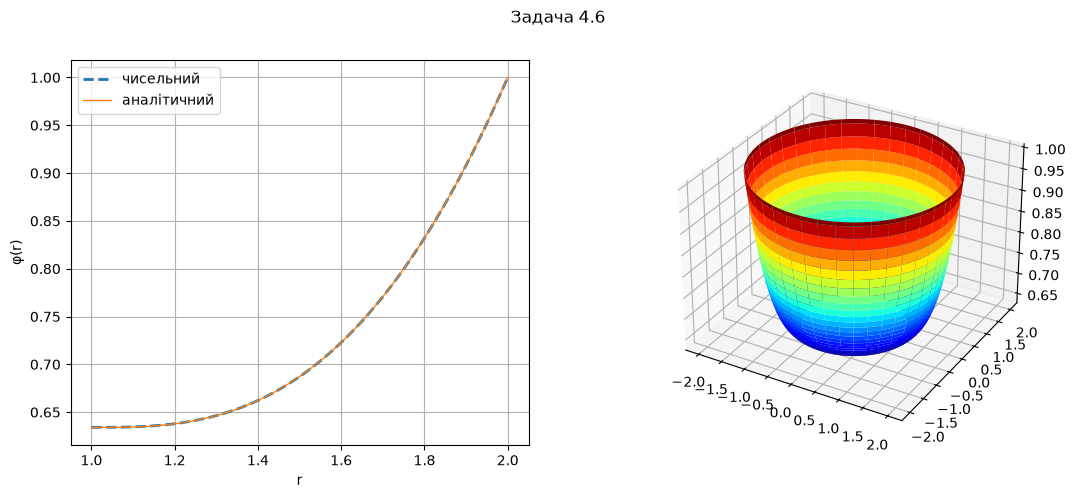

n =   100: max|φ - φ_точн| = 1.176e-03
n =   500: max|φ - φ_точн| = 2.321e-04
n =  1000: max|φ - φ_точн| = 1.152e-04


In [21]:
show_polar(zero, [(1, 0), (2, 0)], [(0, 1), (1, 1)], "Задача 4.6")

#### Модифікація: кільцева пластина під рівномірним тиском $q = -100$, обидва краї защемлені

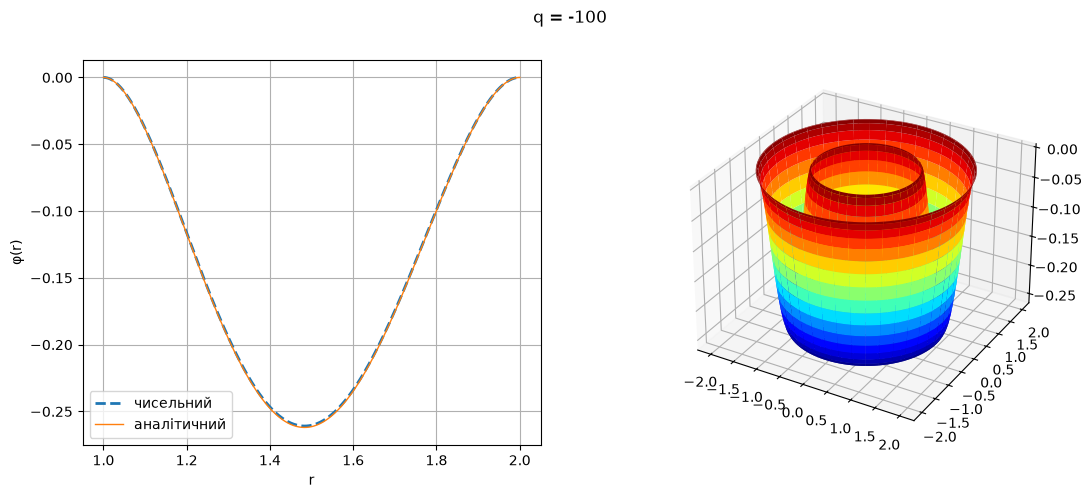

n =   100: max|φ - φ_точн| = 1.042e-02
n =   500: max|φ - φ_точн| = 2.100e-03
n =  1000: max|φ - φ_точн| = 1.051e-03


In [22]:
show_polar(lambda r: -100 + 0 * r, [(0, 0), (1, 0)], [(0, 0), (1, 0)], "q = -100", q=-100)

### Висновки
1. П'ятидіагональна прогонка розв'язує систему за $O(n)$; для всіх задач розділу 2 збіг з аналітичним розв'язком.
2. Граничні умови апроксимовані односторонніми різницями, тому похибка $O(h)$: при збільшенні $n$ удвічі похибка зменшується вдвічі.
3. Внутрішня опора — заміна рівняння у вузлі на $y_i = v$; у балці з'являється реакція (стрибок $y'''$).
4. У 2D 13-точкова схема дає прогин, що збігається до довідкових значень для защемленої і шарнірної пластин.
5. Релаксація дає той самий розв'язок, що і прямий метод, але значно повільніше.
6. У полярних координатах коефіцієнти схеми залежать від $r_i$; результат збігається з аналітичним $C_1 + C_2\ln r + C_3r^2 + C_4r^2\ln r$.